# Resultados Fase 2: Generación de Reportes + Tabla Comparativa Global

Notebook de análisis que consolida:
- **Clasificación**: DenseNet, ViT, LLaVA-Med, Mini-VLM (zero-shot y fine-tuned)
- **Generación de reportes**: Evaluación Nivel 2 (NER clínico) sobre HAM10000
- **Análisis cruzado**: Clasificación vs. calidad de reportes generados

In [25]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuracion de paths
REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))
RESULTS_DIR = REPO_ROOT / "outputs" / "results"
REPORTS_DIR = REPO_ROOT / "outputs" / "generated_reports"

# Estilo de graficos
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (12, 5)

CLASS_NAMES = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]

def load_json(name):
    with open(RESULTS_DIR / name, encoding="utf-8") as f:
        return json.load(f)

# Clasificacion
densenet = load_json("densenet_test_results.json")
vit = load_json("vit_test_results.json")
llava_cls = load_json("llava_med_test_results.json")
llava_ft_cls = load_json("llava_med_finetuned_test_results.json")
mini_cls = load_json("mini_vlm_test_results.json")
mini_ft_cls = load_json("mini_vlm_finetuned_test_results.json")

# Training Stage 2
stage2_llava = load_json("stage2_llava_med_metrics.json")
stage2_mini = load_json("stage2_mini_vlm_metrics.json")

# NER Nivel 2
ner_llava = load_json("level2_llava_med_results.json")
ner_mini = load_json("level2_mini_vlm_results.json")

print("Datos cargados correctamente.")

Datos cargados correctamente.


## 1. Tabla Comparativa Global de Clasificacion

Comparacion de los 5 modelos evaluados sobre el test set de HAM10000 (1503 imagenes, 7 clases).

In [26]:
from src.evaluation.report_builder import build_comparison_table

models_cls = {
    "DenseNet-121": densenet,
    "ViT-B/16": vit,
    "LLaVA-Med (zero-shot)": llava_cls,
    "LLaVA-Med (fine-tuned)": llava_ft_cls,
    "Mini-VLM (zero-shot)": mini_cls,
    "Mini-VLM (fine-tuned)": mini_ft_cls,
}

results_dict = {}
for name, data in models_cls.items():
    results_dict[name] = {
        "accuracy": data["accuracy"],
        "f1_weighted": data["f1_weighted"],
        "sensitivity_macro": data["sensitivity_macro"],
        "specificity_macro": data["specificity_macro"],
    }

metrics_cols = ["accuracy", "f1_weighted", "sensitivity_macro", "specificity_macro"]
df_cls = build_comparison_table(results_dict, metrics_cols)

# Formatear para visualizacion
df_display = df_cls.copy()
for col in metrics_cols:
    df_display[col] = df_display[col].map(lambda x: f"{x:.4f}" if x is not None else "-")

df_display.columns = ["Modelo", "Accuracy", "F1 (weighted)", "Sensibilidad (macro)", "Especificidad (macro)"]
df_display.style.set_caption("Tabla 1: Resultados de clasificacion sobre HAM10000 test set")

,Modelo,Accuracy,F1 (weighted),Sensibilidad (macro),Especificidad (macro)
0,DenseNet-121,0.5230,0.5805,0.3942,0.9198
1,ViT-B/16,0.6314,0.6676,0.5196,0.9326
2,LLaVA-Med (zero-shot),0.1144,0.0296,0.1561,0.8580
3,LLaVA-Med (fine-tuned),0.1111,0.0222,0.1429,0.8571
4,Mini-VLM (zero-shot),0.0512,0.0061,0.1439,0.8571
5,Mini-VLM (fine-tuned),0.1118,0.0236,0.1447,0.8573


## 2. Matrices de Confusion

Matrices de confusion para los 5 modelos. Las filas representan la clase real y las columnas la prediccion.

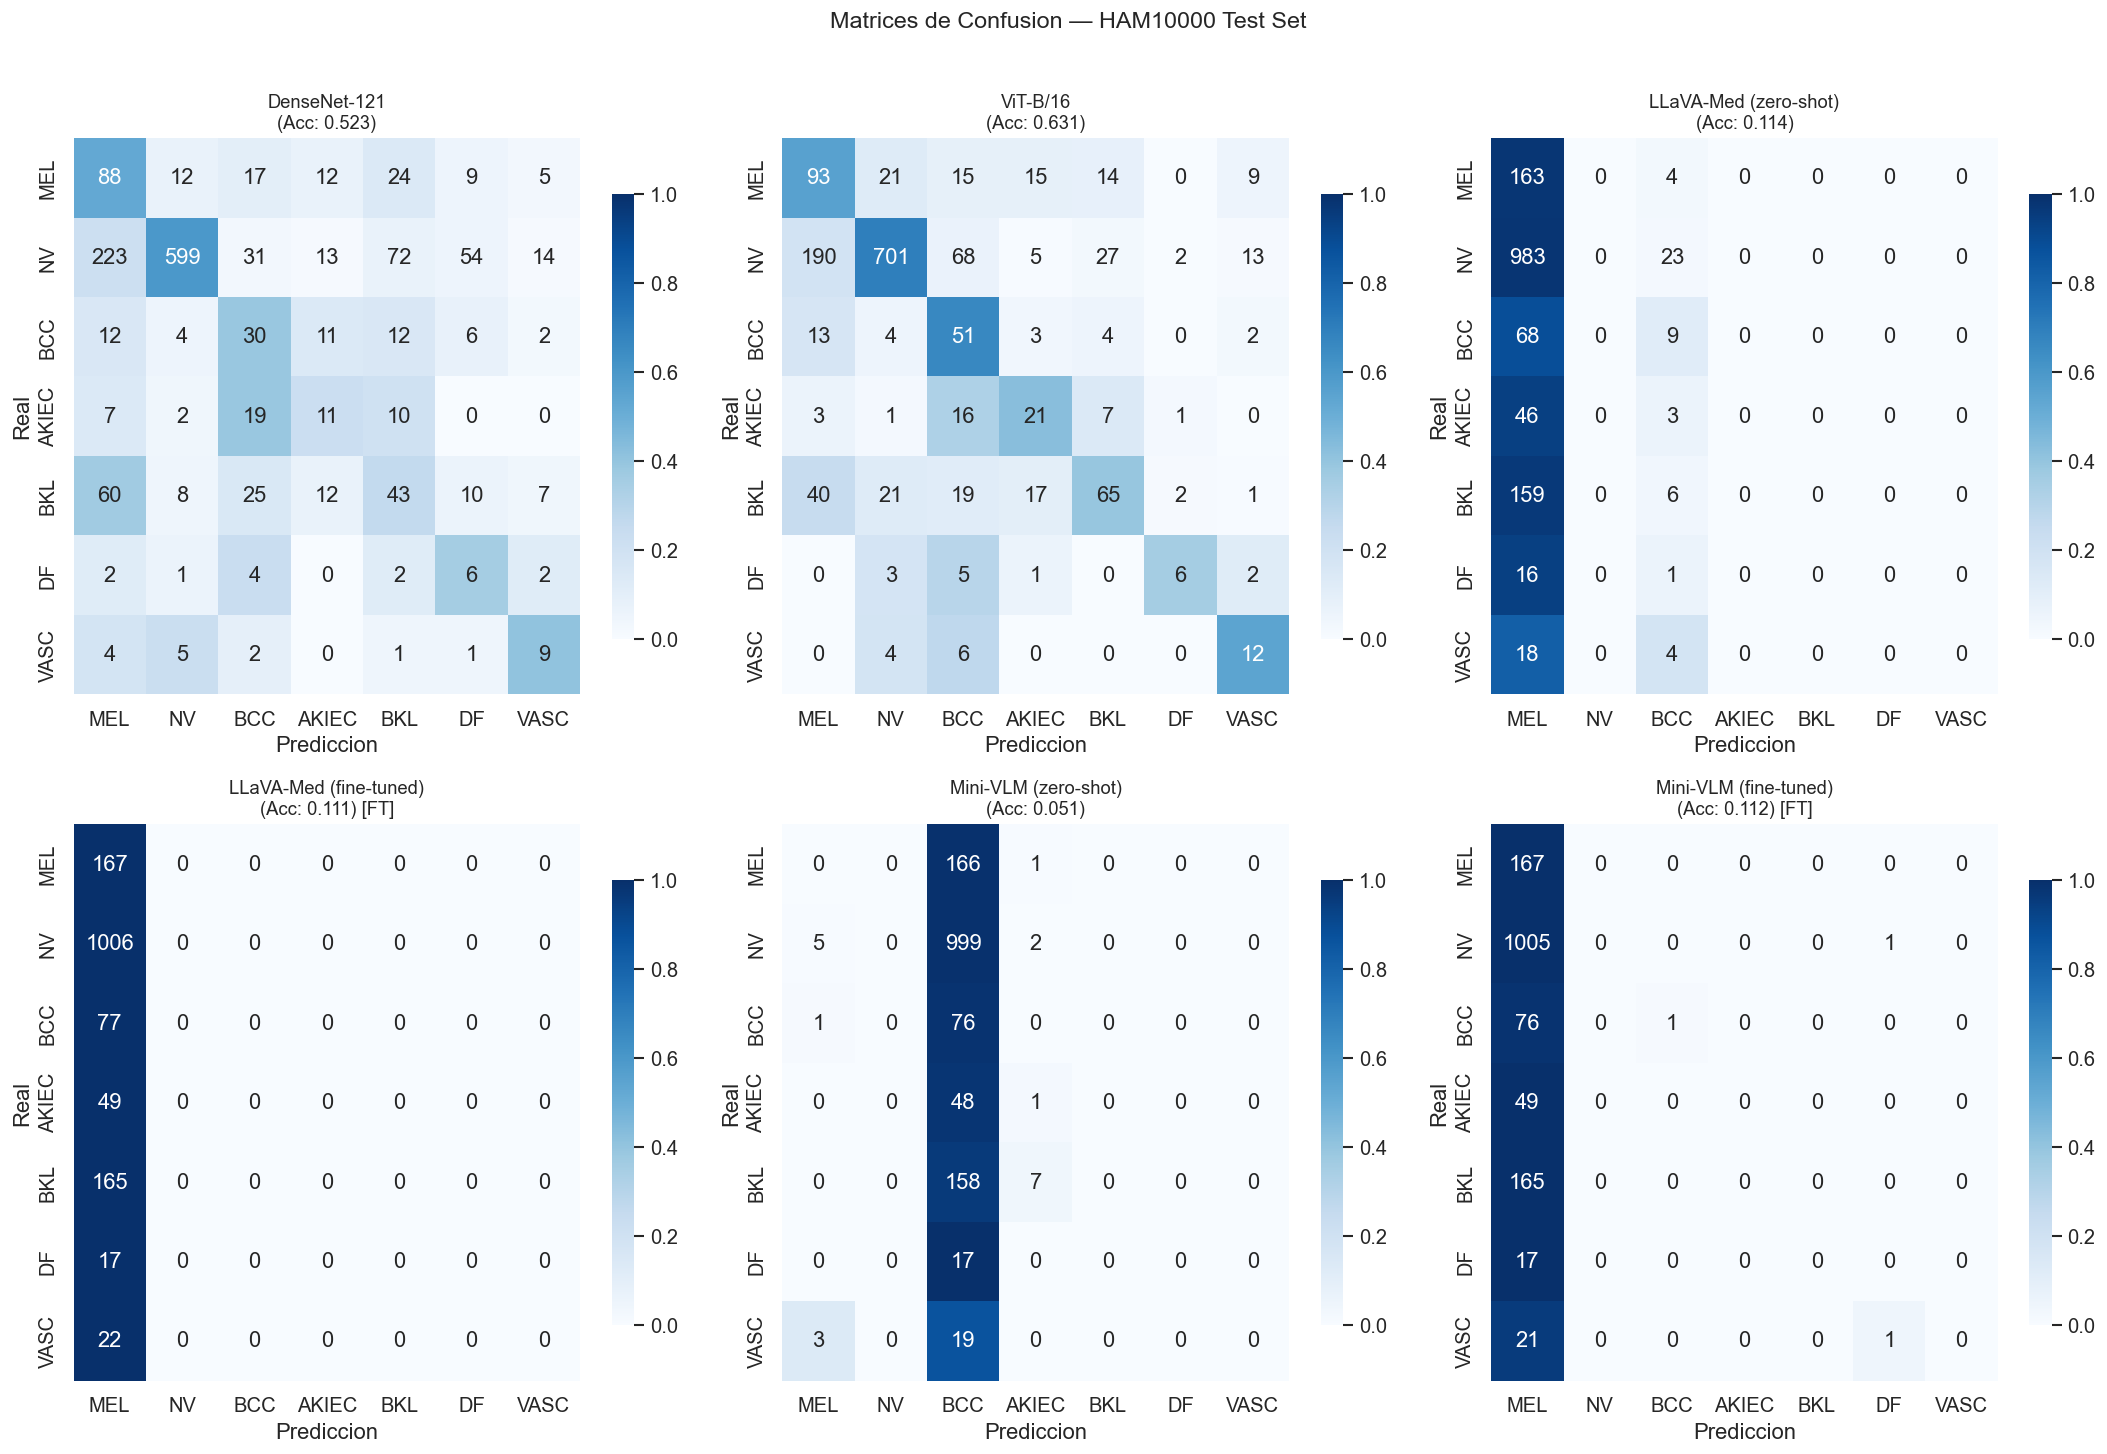

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes_flat = axes.flatten()

for i, (name, data) in enumerate(models_cls.items()):
    ax = axes_flat[i]
    cm = np.array(data["confusion_matrix"])
    # Normalizar por fila (recall)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=cm, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        ax=ax, vmin=0, vmax=1, cbar_kws={"shrink": 0.8},
    )
    acc = data["accuracy"]
    finetuned = data.get("finetuned", False)
    label = f"{name}\n(Acc: {acc:.3f})" + (" [FT]" if finetuned else "")
    ax.set_title(label, fontsize=11)
    ax.set_ylabel("Real")
    ax.set_xlabel("Prediccion")

fig.suptitle("Matrices de Confusion — HAM10000 Test Set", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 3. Sensibilidad por Clase

Comparacion de la sensibilidad (recall) por clase para cada modelo. Esto permite identificar que clases cada modelo detecta mejor o peor.

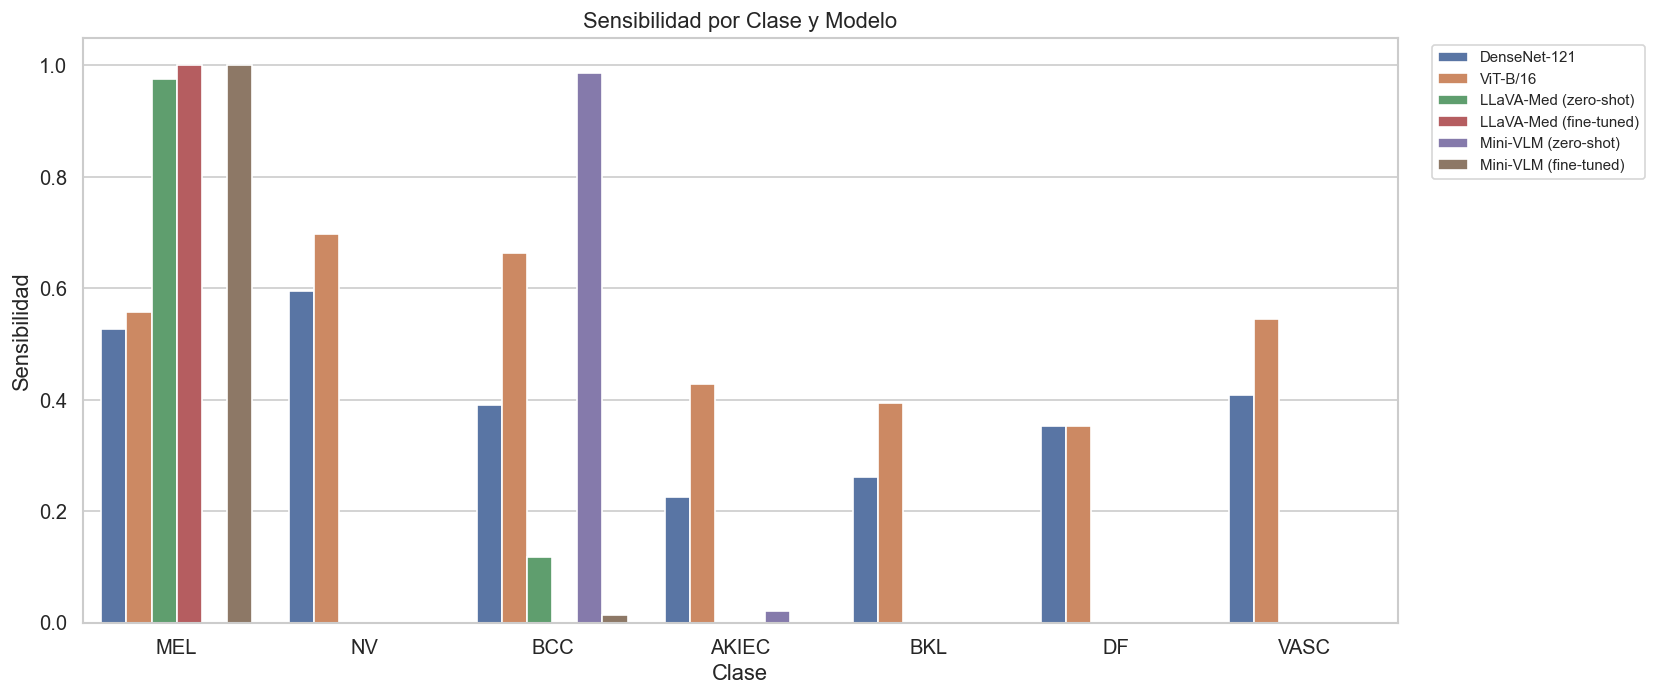

In [28]:
sens_data = []
for name, data in models_cls.items():
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        sens_data.append({
            "Modelo": name,
            "Clase": cls_name,
            "Sensibilidad": data["sensitivity_per_class"][cls_idx],
        })

df_sens = pd.DataFrame(sens_data)

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=df_sens, x="Clase", y="Sensibilidad", hue="Modelo", ax=ax)
ax.set_title("Sensibilidad por Clase y Modelo")
ax.set_ylim(0, 1.05)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 4. Curvas de Entrenamiento — Stage 2 (Fine-tuning con LoRA)

Loss de entrenamiento y validacion durante el fine-tuning Stage 2 con LoRA (r=64, alpha=128) para ambos VLMs.

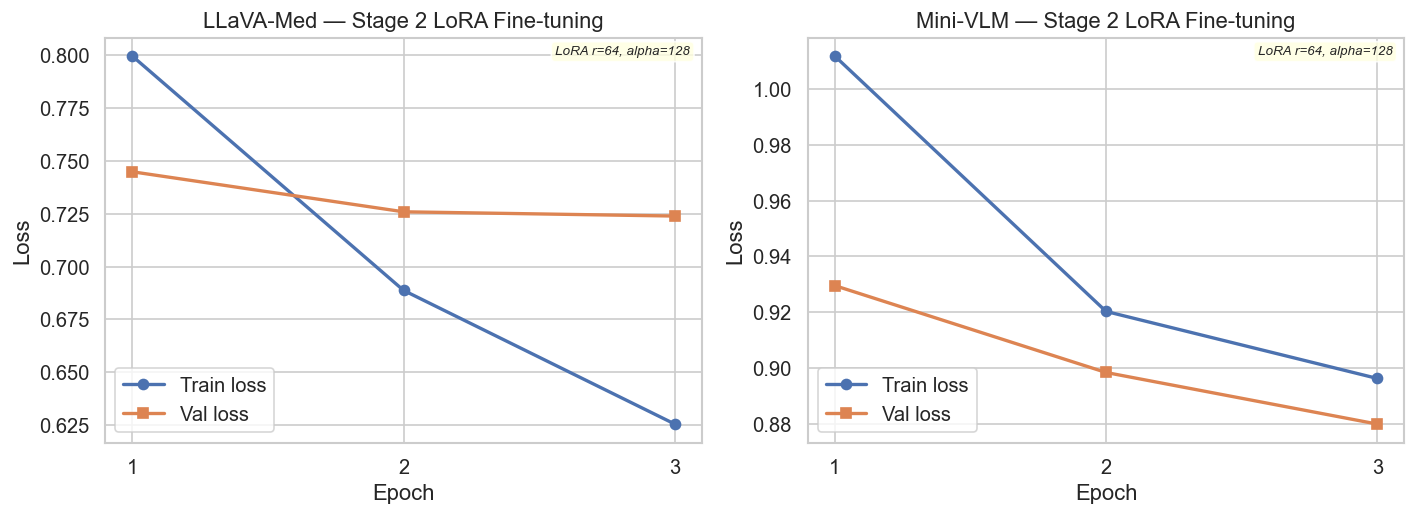

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, data) in zip(axes, [("LLaVA-Med", stage2_llava), ("Mini-VLM", stage2_mini)]):
    epochs = list(range(1, len(data["train_loss"]) + 1))
    ax.plot(epochs, data["train_loss"], "o-", label="Train loss", linewidth=2)
    ax.plot(epochs, data["val_loss"], "s-", label="Val loss", linewidth=2)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title(f"{name} — Stage 2 LoRA Fine-tuning")
    ax.legend()
    ax.set_xticks(epochs)

    # Anotar config LoRA
    lora = data["lora_config"]
    ax.text(
        0.98, 0.98,
        f"LoRA r={lora['r']}, alpha={lora['lora_alpha']}",
        transform=ax.transAxes, ha="right", va="top",
        fontsize=8, style="italic",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", alpha=0.8),
    )

plt.tight_layout()
plt.show()

## 5. Metricas Nivel 2: Evaluacion NER Clinico

Evaluacion sin referencia de los reportes generados sobre HAM10000:
- **Clinical Entity Recall**: Proporcion de categorias de terminos dermatologicos (ABCDE, tipos de lesion, features clinicos) mencionados en los reportes.
- **Diagnostic Consistency**: Porcentaje de reportes donde el diagnostico ground truth (o un sinonimo) aparece en el texto generado.

In [30]:
# Tabla de metricas NER
df_ner = pd.DataFrame([
    {
        "Modelo": "LLaVA-Med",
        "Clinical Entity Recall": ner_llava["clinical_entity_recall"],
        "Diagnostic Consistency": ner_llava["diagnostic_consistency"],
        "N reportes": len(ner_llava["per_report_recall"]),
    },
    {
        "Modelo": "Mini-VLM",
        "Clinical Entity Recall": ner_mini["clinical_entity_recall"],
        "Diagnostic Consistency": ner_mini["diagnostic_consistency"],
        "N reportes": len(ner_mini["per_report_recall"]),
    },
])

df_ner_display = df_ner.copy()
for col in ["Clinical Entity Recall", "Diagnostic Consistency"]:
    df_ner_display[col] = df_ner_display[col].map(lambda x: f"{x:.4f}")
df_ner_display.style.set_caption("Tabla 2: Metricas Nivel 2 (NER clinico) sobre HAM10000")

,Modelo,Clinical Entity Recall,Diagnostic Consistency,N reportes
0,LLaVA-Med,0.4569,0.7147,3042
1,Mini-VLM,0.6068,0.3134,2240


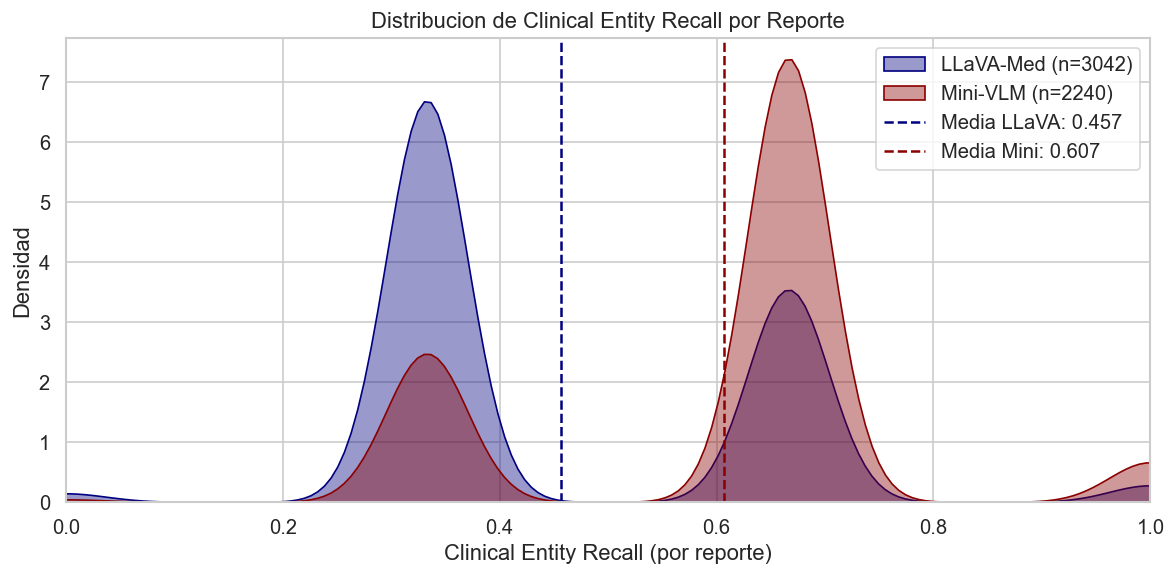

In [31]:
# Distribucion de clinical entity recall por reporte
fig, ax = plt.subplots(figsize=(10, 5))

sns.kdeplot(ner_llava["per_report_recall"], fill=True, alpha=0.4, label=f"LLaVA-Med (n={len(ner_llava['per_report_recall'])})", color="navy", ax=ax)
sns.kdeplot(ner_mini["per_report_recall"], fill=True, alpha=0.4, label=f"Mini-VLM (n={len(ner_mini['per_report_recall'])})", color="darkred", ax=ax)

ax.axvline(ner_llava["clinical_entity_recall"], color="navy", linestyle="--", linewidth=1.5, label=f"Media LLaVA: {ner_llava['clinical_entity_recall']:.3f}")
ax.axvline(ner_mini["clinical_entity_recall"], color="darkred", linestyle="--", linewidth=1.5, label=f"Media Mini: {ner_mini['clinical_entity_recall']:.3f}")

ax.set_xlabel("Clinical Entity Recall (por reporte)")
ax.set_ylabel("Densidad")
ax.set_title("Distribucion de Clinical Entity Recall por Reporte")
ax.set_xlim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Ejemplos de Reportes Generados

Comparacion side-by-side de reportes generados por LLaVA-Med y Mini-VLM para las mismas imagenes, con una muestra por cada clase diagnostica.

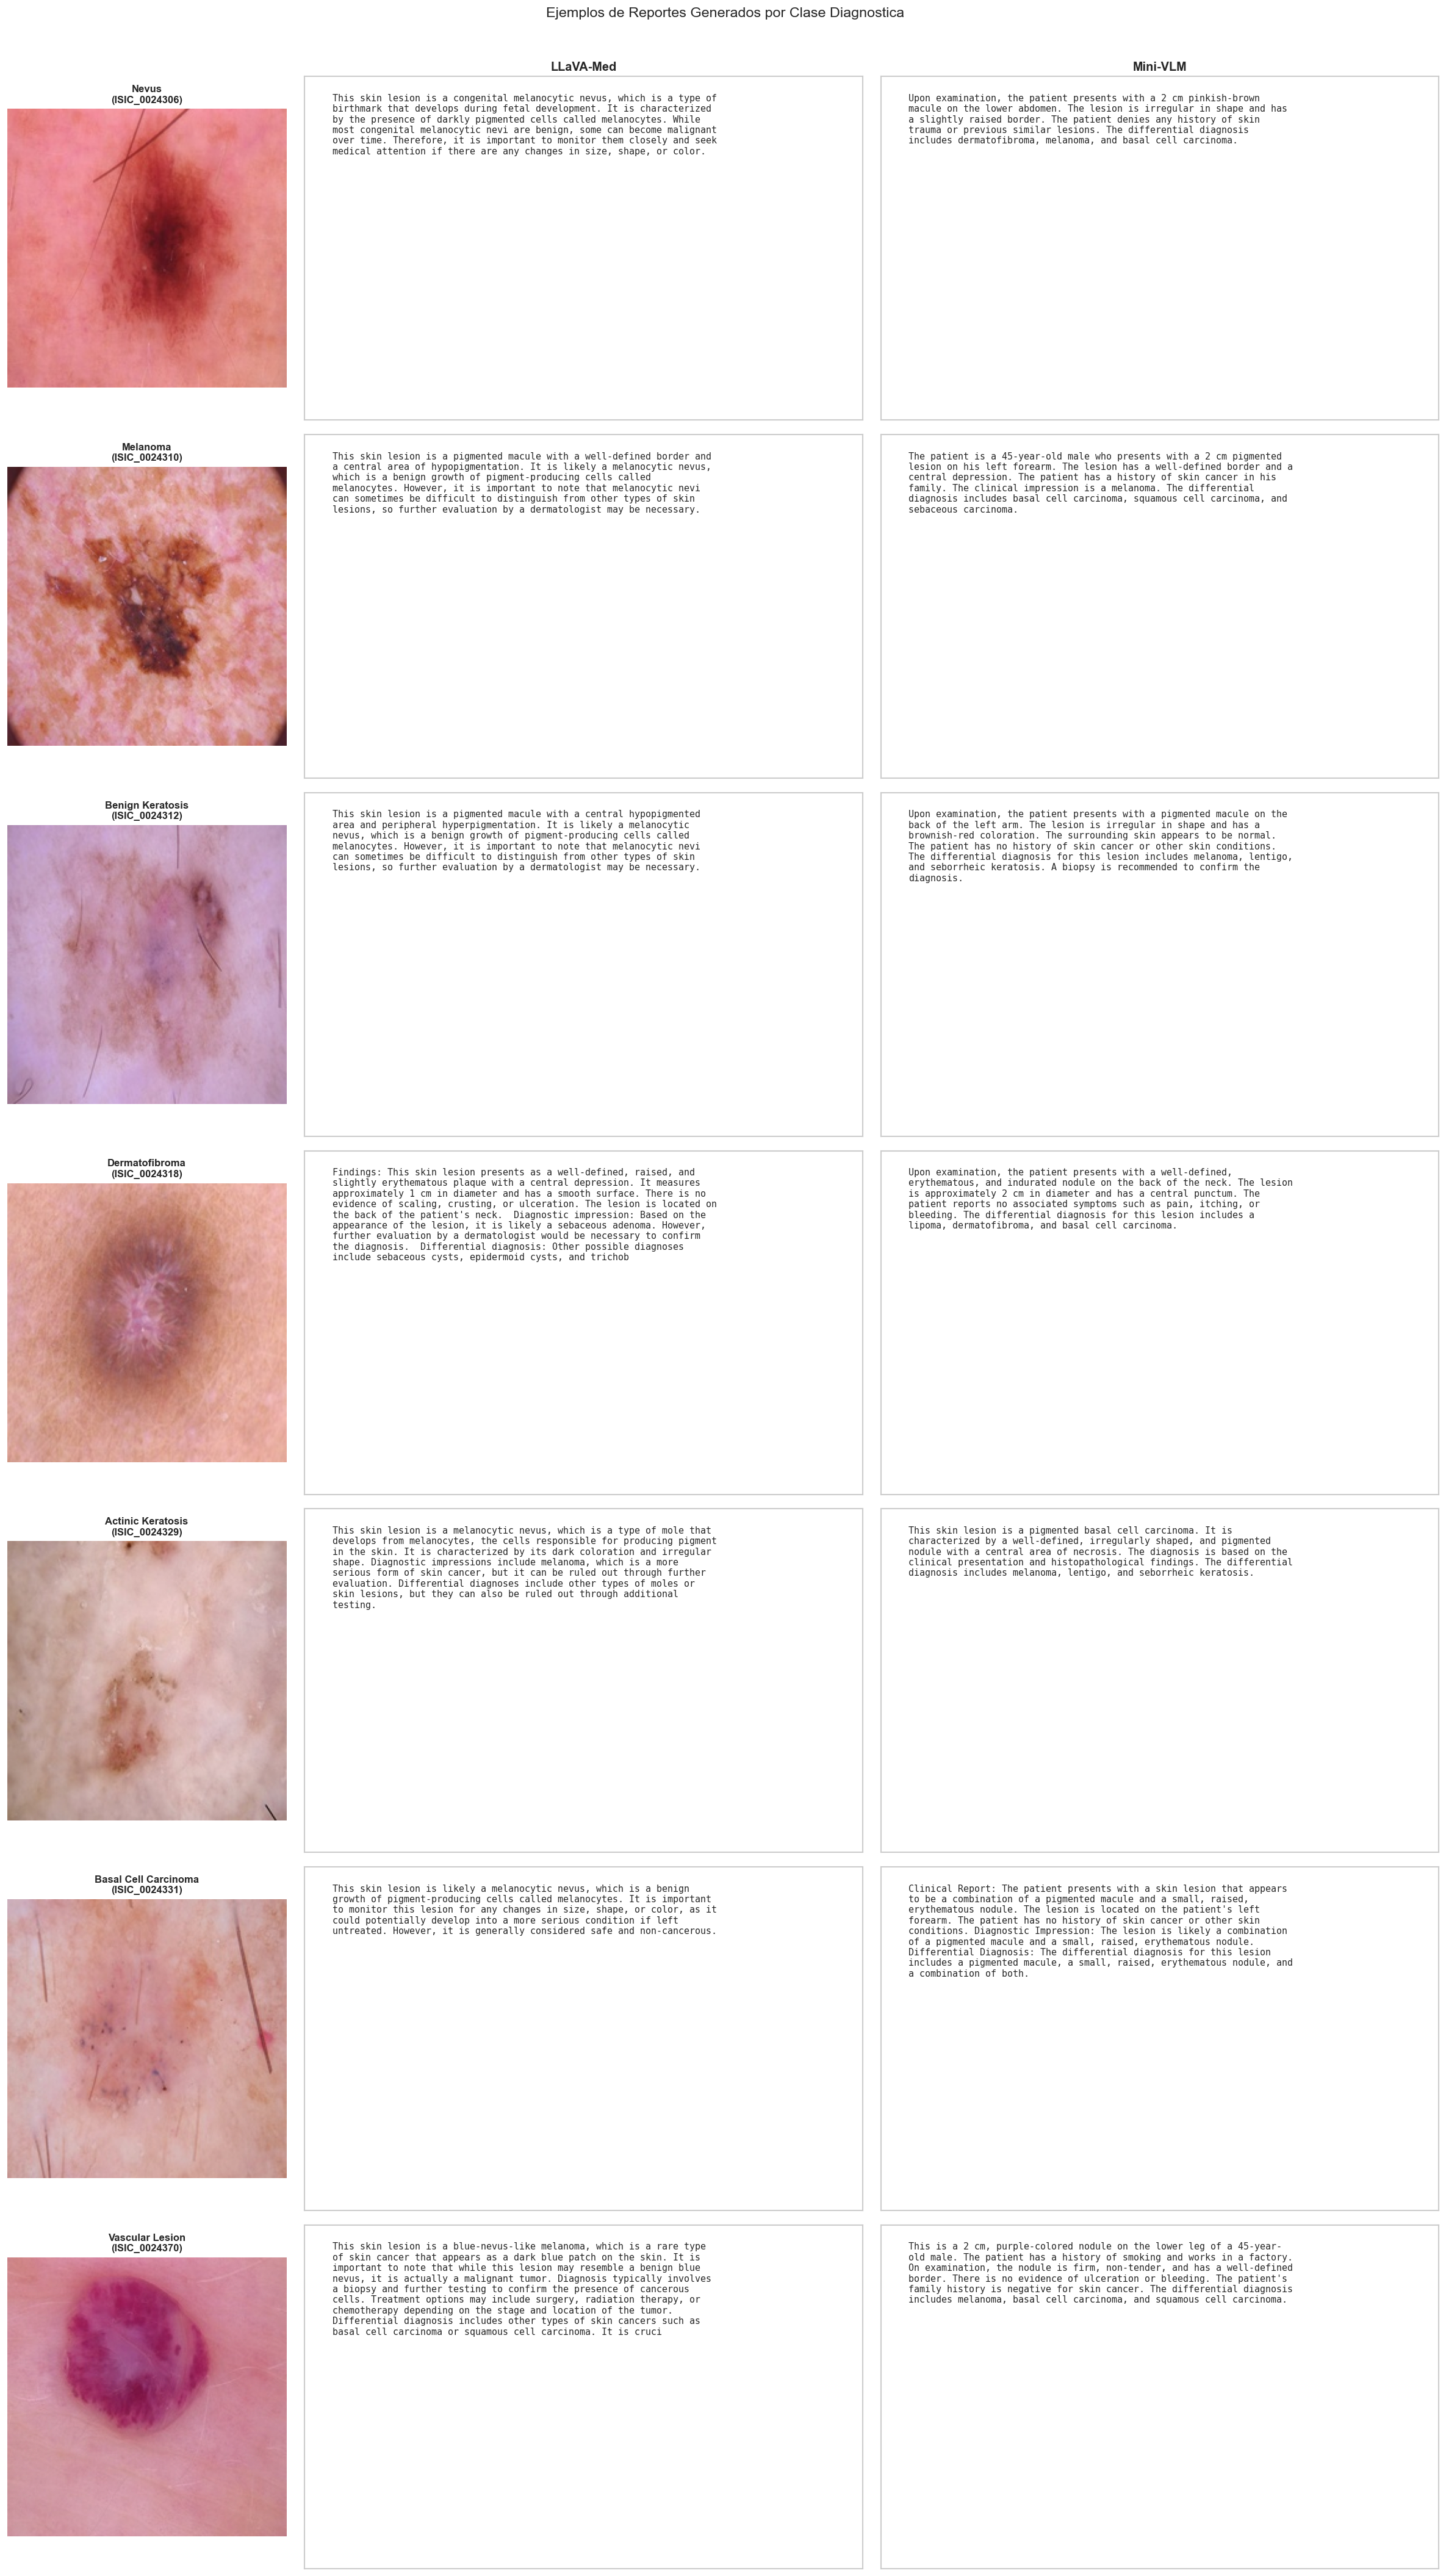

In [32]:
import textwrap

# Seleccionar un ejemplo por clase diagnostica
sample_ids = {
    "nevus": "ISIC_0024306",
    "melanoma": "ISIC_0024310",
    "benign keratosis": "ISIC_0024312",
    "dermatofibroma": "ISIC_0024318",
    "actinic keratosis": "ISIC_0024329",
    "basal cell carcinoma": "ISIC_0024331",
    "vascular lesion": "ISIC_0024370",
}

IMAGE_DIR = REPO_ROOT / "data" / "processed" / "HAM10000"

fig, axes = plt.subplots(
    len(sample_ids), 3, figsize=(20, 5 * len(sample_ids)),
    gridspec_kw={"width_ratios": [1, 2, 2]},
)

for row, (gt_label, image_id) in enumerate(sample_ids.items()):
    # Cargar imagen
    img_path = IMAGE_DIR / f"{image_id}.jpg"
    img = plt.imread(str(img_path))
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"{gt_label.title()}\n({image_id})", fontsize=10, fontweight="bold")
    axes[row, 0].axis("off")

    # Cargar reportes
    llava_path = REPORTS_DIR / "llava_med" / "HAM10000" / f"{image_id}_report.json"
    mini_path = REPORTS_DIR / "mini_vlm" / "HAM10000" / f"{image_id}_report.json"

    llava_report = json.load(open(llava_path, encoding="utf-8"))["report"].strip()
    mini_report = json.load(open(mini_path, encoding="utf-8"))["report"].strip()

    # Mostrar reportes como texto
    for col, (model_name, report) in enumerate([("LLaVA-Med", llava_report), ("Mini-VLM", mini_report)], start=1):
        ax = axes[row, col]
        wrapped = textwrap.fill(report[:600], width=70)
        ax.text(
            0.05, 0.95, wrapped,
            transform=ax.transAxes, fontsize=9,
            verticalalignment="top", fontfamily="monospace",
            wrap=True,
        )
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(model_name, fontsize=12, fontweight="bold")

fig.suptitle("Ejemplos de Reportes Generados por Clase Diagnostica", fontsize=14, y=1.005)
plt.tight_layout()
plt.show()

## 7. Analisis Cruzado: Clasificacion vs. Calidad de Reportes

Comparacion entre la capacidad de clasificacion (F1) y la calidad de los reportes generados (NER) para los VLMs. La pregunta clave: **los modelos que mejor clasifican, generan mejores reportes?**

In [33]:
# Tabla cruzada: clasificacion + NER
df_cross = pd.DataFrame([
    {
        "Modelo": "LLaVA-Med (zero-shot)",
        "Accuracy (cls)": llava_cls["accuracy"],
        "F1 weighted (cls)": llava_cls["f1_weighted"],
        "Clinical Entity Recall": ner_llava["clinical_entity_recall"],
        "Diagnostic Consistency": ner_llava["diagnostic_consistency"],
    },
    {
        "Modelo": "LLaVA-Med (fine-tuned)",
        "Accuracy (cls)": llava_ft_cls["accuracy"],
        "F1 weighted (cls)": llava_ft_cls["f1_weighted"],
        "Clinical Entity Recall": ner_llava["clinical_entity_recall"],
        "Diagnostic Consistency": ner_llava["diagnostic_consistency"],
    },
    {
        "Modelo": "Mini-VLM (fine-tuned)",
        "Accuracy (cls)": mini_ft_cls["accuracy"],
        "F1 weighted (cls)": mini_ft_cls["f1_weighted"],
        "Clinical Entity Recall": ner_mini["clinical_entity_recall"],
        "Diagnostic Consistency": ner_mini["diagnostic_consistency"],
    },
])

df_cross_display = df_cross.copy()
for col in df_cross.columns[1:]:
    df_cross_display[col] = df_cross_display[col].map(lambda x: f"{x:.4f}")

df_cross_display.style.set_caption("Tabla 4: Clasificacion vs. Calidad de Reportes (VLMs)")

,Modelo,Accuracy (cls),F1 weighted (cls),Clinical Entity Recall,Diagnostic Consistency
0,LLaVA-Med (zero-shot),0.1144,0.0296,0.4569,0.7147
1,LLaVA-Med (fine-tuned),0.1111,0.0222,0.4569,0.7147
2,Mini-VLM (fine-tuned),0.1118,0.0236,0.6068,0.3134


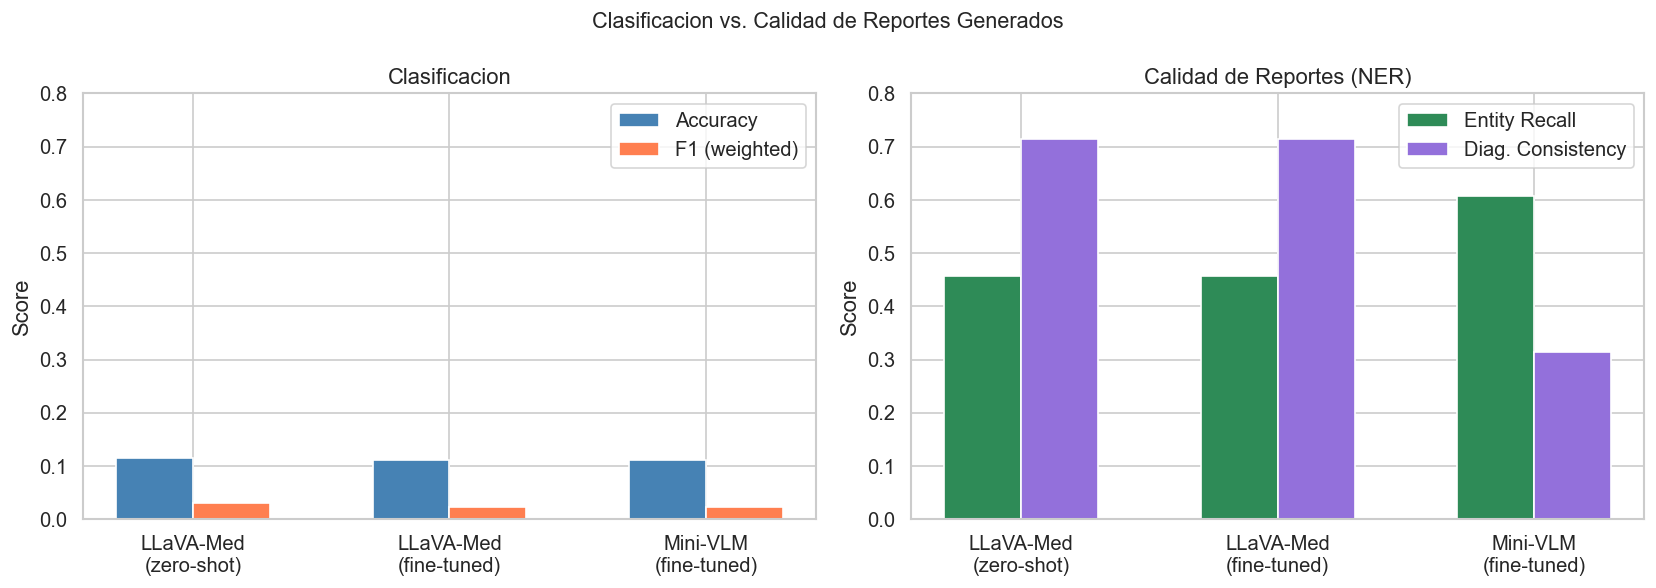

In [34]:
# Grafico comparativo: barras agrupadas clasificacion vs. NER
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

models_labels = [
    "LLaVA-Med\n(zero-shot)",
    "LLaVA-Med\n(fine-tuned)",
    "Mini-VLM\n(fine-tuned)",
]
x = np.arange(len(models_labels))
width = 0.3

# Clasificacion
acc_vals = [llava_cls["accuracy"], llava_ft_cls["accuracy"], mini_ft_cls["accuracy"]]
f1_vals  = [llava_cls["f1_weighted"], llava_ft_cls["f1_weighted"], mini_ft_cls["f1_weighted"]]
ax1.bar(x - width/2, acc_vals, width, label="Accuracy", color="steelblue")
ax1.bar(x + width/2, f1_vals,  width, label="F1 (weighted)", color="coral")
ax1.set_ylabel("Score")
ax1.set_title("Clasificacion")
ax1.set_xticks(x)
ax1.set_xticklabels(models_labels)
ax1.legend()
ax1.set_ylim(0, 0.8)

# NER — LLaVA fine-tuned comparte metricas NER con LLaVA zero-shot (mismos reportes generados)
entity_vals = [ner_llava["clinical_entity_recall"], ner_llava["clinical_entity_recall"], ner_mini["clinical_entity_recall"]]
diag_vals   = [ner_llava["diagnostic_consistency"], ner_llava["diagnostic_consistency"], ner_mini["diagnostic_consistency"]]
ax2.bar(x - width/2, entity_vals, width, label="Entity Recall", color="seagreen")
ax2.bar(x + width/2, diag_vals,   width, label="Diag. Consistency", color="mediumpurple")
ax2.set_ylabel("Score")
ax2.set_title("Calidad de Reportes (NER)")
ax2.set_xticks(x)
ax2.set_xticklabels(models_labels)
ax2.legend()
ax2.set_ylim(0, 0.8)

fig.suptitle("Clasificacion vs. Calidad de Reportes Generados", fontsize=13)
plt.tight_layout()
plt.show()

## 8. Observaciones

**Clasificacion:**
- Los clasificadores tradicionales (ViT, DenseNet) superan ampliamente a los VLMs en clasificacion directa sobre HAM10000.
- Los VLMs colapsan a 1-2 clases en zero-shot: LLaVA-Med predice ~96.5% como MEL, Mini-VLM predice ~98.7% como BCC.
- El fine-tuning para clasificacion directa **no resuelve el problema en ninguno de los dos VLMs**:
  - Mini-VLM fine-tuned: colapsa a MEL (1.500/1.503 predicciones), acc=11.18%
  - LLaVA-Med fine-tuned: colapso completo a MEL (1.503/1.503 predicciones, spec MEL=0.0), acc=11.11%
  - El fine-tuning agrava el colapso: LLaVA-Med pasa de 1.450 a 1.503 predicciones MEL
- ViT (63.1% acc, 0.668 F1) es el mejor clasificador, seguido por DenseNet (52.3% acc, 0.581 F1).

**Generacion de reportes (Nivel 2 NER):**
- LLaVA-Med tiene mayor **diagnostic consistency** (0.715 vs 0.313): menciona el diagnostico correcto en ~71% de los reportes.
- Mini-VLM tiene mayor **clinical entity recall** (0.607 vs 0.457): usa terminologia clinica mas variada.
- Este trade-off sugiere que LLaVA-Med es mas preciso en diagnostico pero menos detallado en descripcion, mientras Mini-VLM genera reportes morfologicamente mas ricos pero con menor precision diagnostica.

**Analisis cruzado:**
- Todos los VLMs clasifican pobremente (acc < 12%) pero LLaVA-Med genera reportes clinicamente razonables (entity recall 45.7%, diag consistency 71.5%).
- El fine-tuning para clasificacion (etiqueta directa) deteriora aun mas el comportamiento frente al zero-shot, sugiriendo que forzar a un VLM a responder con un codigo discreto no es el enfoque correcto.
- La generacion de texto libre es una tarea mas adecuada para los VLMs que la clasificacion forzada en categorias discretas.